In [1]:
import mne

print("MNE version:", mne.__version__)

MNE version: 1.13.2


In [2]:
from pathlib import Path

# プロジェクトのデータフォルダを指定
data_dir = Path.cwd().parent / "data" / "raw"

# 脳波データのファイルパス
psg_path = data_dir / "SC4001E0-PSG.edf"

# ファイルが存在するか確認
print("ファイルの場所:", psg_path)
print("ファイルが存在する:", psg_path.exists())

# EDFファイルを読み込む
raw = mne.io.read_raw_edf(psg_path, preload=False)

# データの基本情報を表示
print(raw.info)

ファイルの場所: c:\Users\NDF10\Desktop\sleep-stage-clustering\data\raw\SC4001E0-PSG.edf
ファイルが存在する: True
Extracting EDF parameters from c:\Users\NDF10\Desktop\sleep-stage-clustering\data\raw\SC4001E0-PSG.edf...
Setting channel info structure...
Creating raw.info structure...
<Info | 8 non-empty values
 bads: []
 ch_names: EEG Fpz-Cz, EEG Pz-Oz, EOG horizontal, Resp oro-nasal, EMG ...
 chs: 7 EEG
 custom_ref_applied: False
 highpass: 0.0 Hz
 lowpass: 50.0 Hz
 meas_date: 1989-04-24 16:13:00 UTC
 nchan: 7
 projs: []
 sfreq: 100.0 Hz
 subject_info: <subject_info | his_id: X, sex: 2, first_name: Female, last_name: 33yr>
>


C:\Users\NDF10\AppData\Local\Temp\ipykernel_12676\2924431186.py:14: RuntimeWarning: Channels contain different highpass filters. Highest filter setting will be stored.
  raw = mne.io.read_raw_edf(psg_path, preload=False)
C:\Users\NDF10\AppData\Local\Temp\ipykernel_12676\2924431186.py:14: RuntimeWarning: Channels contain different lowpass filters. Lowest filter setting will be stored.
  raw = mne.io.read_raw_edf(psg_path, preload=False)
C:\Users\NDF10\AppData\Local\Temp\ipykernel_12676\2924431186.py:14: RuntimeWarning: Highpass cutoff frequency 16.0 is greater than lowpass cutoff frequency 0.7, setting values to 0 and Nyquist.
  raw = mne.io.read_raw_edf(psg_path, preload=False)


In [3]:
# 記録されているチャンネル名
print("チャンネル一覧:")
for ch in raw.ch_names:
    print("-", ch)

# データの基本情報
print("\nサンプリング周波数:", raw.info["sfreq"], "Hz")
print("記録時間:", round(raw.times[-1] / 3600, 2), "時間")
print("データのサンプル数:", raw.n_times)

チャンネル一覧:
- EEG Fpz-Cz
- EEG Pz-Oz
- EOG horizontal
- Resp oro-nasal
- EMG submental
- Temp rectal
- Event marker

サンプリング周波数: 100.0 Hz
記録時間: 22.08 時間
データのサンプル数: 7950000


In [4]:
# 睡眠段階ラベルのファイル
hypnogram_path = data_dir / "SC4001EC-Hypnogram.edf"

# 睡眠段階の注釈データを読み込む
annotations = mne.read_annotations(hypnogram_path)

# 注釈の基本情報
print("注釈の数:", len(annotations))
print("\n睡眠段階の種類:")
print(sorted(set(annotations.description)))

# 最初の10件を確認
print("\n最初の10件:")
for ann in list(annotations)[:10]:
    print(ann)

注釈の数: 154

睡眠段階の種類:
['Sleep stage 1', 'Sleep stage 2', 'Sleep stage 3', 'Sleep stage 4', 'Sleep stage ?', 'Sleep stage R', 'Sleep stage W']

最初の10件:
OrderedDict([('onset', np.float64(0.0)), ('duration', np.float64(30630.0)), ('description', 'Sleep stage W'), ('orig_time', None), ('extras', {})])
OrderedDict([('onset', np.float64(30630.0)), ('duration', np.float64(120.0)), ('description', 'Sleep stage 1'), ('orig_time', None), ('extras', {})])
OrderedDict([('onset', np.float64(30750.0)), ('duration', np.float64(390.0)), ('description', 'Sleep stage 2'), ('orig_time', None), ('extras', {})])
OrderedDict([('onset', np.float64(31140.0)), ('duration', np.float64(30.0)), ('description', 'Sleep stage 3'), ('orig_time', None), ('extras', {})])
OrderedDict([('onset', np.float64(31170.0)), ('duration', np.float64(30.0)), ('description', 'Sleep stage 2'), ('orig_time', None), ('extras', {})])
OrderedDict([('onset', np.float64(31200.0)), ('duration', np.float64(150.0)), ('description', 'Sleep stag

In [5]:
import pandas as pd

# 睡眠段階の注釈を表に変換
df_annotations = pd.DataFrame({
    "onset": annotations.onset,
    "duration": annotations.duration,
    "stage": annotations.description
})

# 睡眠段階ごとの記録時間を集計
stage_summary = (
    df_annotations
    .groupby("stage")["duration"]
    .sum()
    .div(60)
    .sort_values(ascending=False)
    .reset_index(name="duration_min")
)

# 各睡眠段階の割合を計算
stage_summary["percentage"] = (
    stage_summary["duration_min"]
    / stage_summary["duration_min"].sum()
    * 100
).round(2)

display(stage_summary)

,stage,duration_min,percentage
0,Sleep stage W,998.5,69.34
1,Sleep stage 2,125.0,8.68
2,Sleep stage ?,115.0,7.99
3,Sleep stage R,62.5,4.34
4,Sleep stage 4,59.5,4.13
5,Sleep stage 3,50.5,3.51
6,Sleep stage 1,29.0,2.01


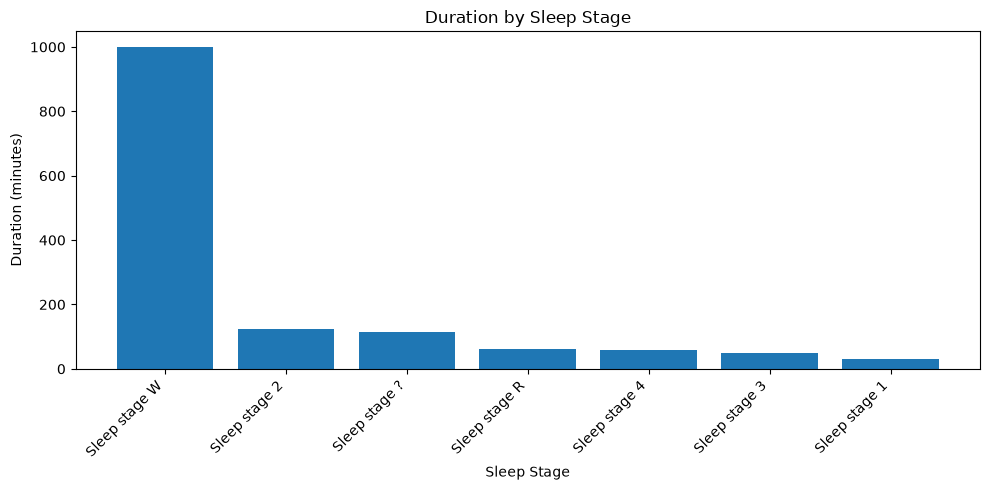

In [6]:
import matplotlib.pyplot as plt

# 睡眠段階ごとの記録時間を棒グラフで表示
plt.figure(figsize=(10, 5))

plt.bar(
    stage_summary["stage"],
    stage_summary["duration_min"]
)

plt.title("Duration by Sleep Stage")
plt.xlabel("Sleep Stage")
plt.ylabel("Duration (minutes)")

plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [7]:
import pandas as pd

# 睡眠段階の注釈をDataFrameに変換
annotations_df = pd.DataFrame({
    "onset": annotations.onset,
    "duration": annotations.duration,
    "stage": annotations.description
})

# 睡眠段階（Wと判定不能を除く）
sleep_stages = [
    "Sleep stage 1",
    "Sleep stage 2",
    "Sleep stage 3",
    "Sleep stage 4",
    "Sleep stage R"
]

# 睡眠が記録された区間を抽出
sleep_df = annotations_df[
    annotations_df["stage"].isin(sleep_stages)
]

# 最初の睡眠開始時刻
sleep_start = sleep_df["onset"].min()

# 最後の睡眠終了時刻
sleep_end = (
    sleep_df["onset"] + sleep_df["duration"]
).max()

# 時間単位に変換
analysis_hours = (sleep_end - sleep_start) / 3600

print(f"睡眠開始位置：{sleep_start / 3600:.2f} 時間")
print(f"睡眠終了位置：{sleep_end / 3600:.2f} 時間")
print(f"分析対象の時間幅：{analysis_hours:.2f} 時間")

睡眠開始位置：8.51 時間
睡眠終了位置：14.52 時間
分析対象の時間幅：6.01 時間


記録時間は約22.08時間だったが、睡眠段階の注釈から最初の睡眠開始位置と最後の睡眠終了位置を特定した結果、分析対象となる時間幅は約6.01時間だった。睡眠段階として記録された時間の合計は約5.44時間であり、睡眠前後の長い覚醒時間を除外することで、分析対象を絞り込めた。

In [8]:
import numpy as np

# EEG（脳波）チャンネルだけを選択
eeg_channels = ["EEG Fpz-Cz", "EEG Pz-Oz"]

# 睡眠開始・終了位置を30秒単位にそろえる
epoch_length = 30

start_sec = np.ceil(sleep_start / epoch_length) * epoch_length
end_sec = np.floor(sleep_end / epoch_length) * epoch_length

# EEGデータを取得
# get_dataの時間指定はサンプル番号で行う
sfreq = raw.info["sfreq"]

start_sample = int(start_sec * sfreq)
end_sample = int(end_sec * sfreq)

eeg_data = raw.get_data(
    picks=eeg_channels,
    start=start_sample,
    stop=end_sample
)

# 30秒あたりのサンプル数
samples_per_epoch = int(epoch_length * sfreq)

# エポック数
n_epochs = eeg_data.shape[1] // samples_per_epoch

# 30秒単位に分割
epochs_data = eeg_data[
    :,
    :n_epochs * samples_per_epoch
].reshape(
    len(eeg_channels),
    n_epochs,
    samples_per_epoch
)

# (エポック数, チャンネル数, サンプル数) に並べ替え
epochs_data = np.transpose(epochs_data, (1, 0, 2))

print("EEGチャンネル数:", len(eeg_channels))
print("エポック数:", n_epochs)
print("1エポックのサンプル数:", samples_per_epoch)
print("データ形状:", epochs_data.shape)

EEGチャンネル数: 2
エポック数: 721
1エポックのサンプル数: 3000
データ形状: (721, 2, 3000)


In [9]:
# 各エポックの開始時刻（秒）
epoch_starts = start_sec + np.arange(n_epochs) * epoch_length

# 睡眠段階ラベルを格納
epoch_labels = []

for epoch_start in epoch_starts:
    epoch_end = epoch_start + epoch_length
    label = "Unknown"

    for ann in annotations:
        ann_start = ann["onset"]
        ann_end = ann_start + ann["duration"]

        # エポック全体が同じ睡眠段階に含まれる場合
        if ann_start <= epoch_start and epoch_end <= ann_end:
            label = ann["description"]
            break

    epoch_labels.append(label)

# ラベルを表にまとめる
epoch_df = pd.DataFrame({
    "epoch": np.arange(n_epochs),
    "start_sec": epoch_starts,
    "stage": epoch_labels
})

print("エポック数:", len(epoch_df))
print("\n睡眠段階ごとのエポック数:")
print(epoch_df["stage"].value_counts())

エポック数: 721

睡眠段階ごとのエポック数:
stage
Sleep stage 2    250
Sleep stage R    125
Sleep stage 4    119
Sleep stage 3    101
Sleep stage W     68
Sleep stage 1     58
Name: count, dtype: int64


In [10]:
# 睡眠段階を5種類に統合
stage_mapping = {
    "Sleep stage W": "W",
    "Sleep stage 1": "N1",
    "Sleep stage 2": "N2",
    "Sleep stage 3": "N3",
    "Sleep stage 4": "N3",
    "Sleep stage R": "REM"
}

# ラベルを変換
epoch_df["stage_5"] = epoch_df["stage"].map(stage_mapping)

# 睡眠段階ごとの件数を確認
print("睡眠段階ごとのエポック数:")
print(epoch_df["stage_5"].value_counts())

# ラベルが付かなかった区間を確認
print("\nラベルなし:", epoch_df["stage_5"].isna().sum())

# データの先頭を確認
display(epoch_df.head())

睡眠段階ごとのエポック数:
stage_5
N2     250
N3     220
REM    125
W       68
N1      58
Name: count, dtype: int64

ラベルなし: 0


,epoch,start_sec,stage,stage_5
0,0,30630.0,Sleep stage 1,N1
1,1,30660.0,Sleep stage 1,N1
2,2,30690.0,Sleep stage 1,N1
3,3,30720.0,Sleep stage 1,N1
4,4,30750.0,Sleep stage 2,N2


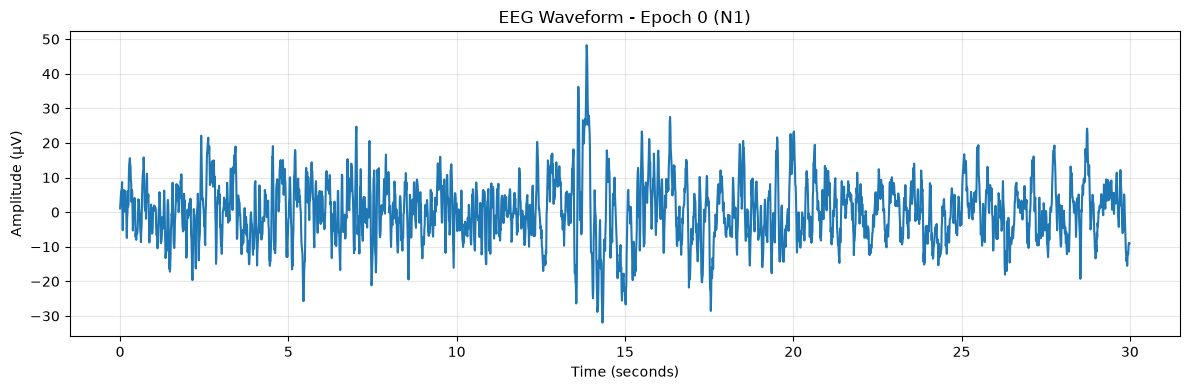

In [11]:
import matplotlib.pyplot as plt

# 最初のエポックを取得
epoch_index = 0

# 時間軸（秒）
time_axis = np.arange(samples_per_epoch) / sfreq

# EEG Fpz-Czの脳波データ
signal = epochs_data[epoch_index, 0, :]

# MNEのデータはV単位なのでμVに変換
signal_uv = signal * 1e6

plt.figure(figsize=(12, 4))

plt.plot(time_axis, signal_uv)

plt.title(
    f"EEG Waveform - Epoch {epoch_index} "
    f"({epoch_df.loc[epoch_index, 'stage_5']})"
)

plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude (μV)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

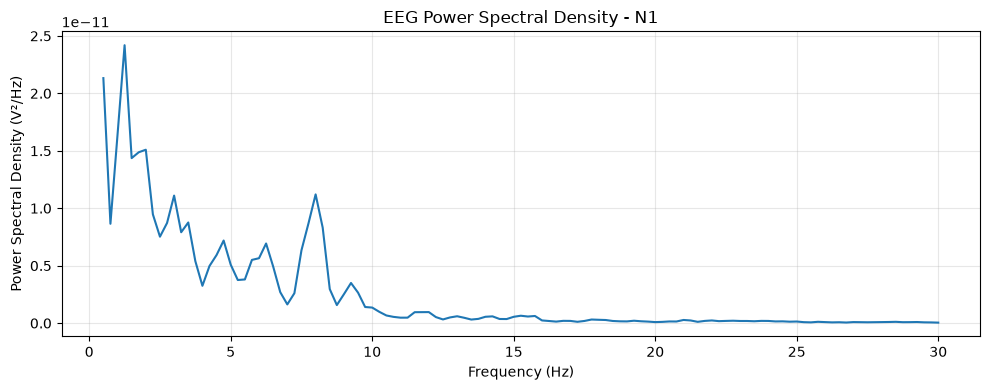

In [12]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import welch

# 最初の30秒間の脳波を取得
# 形状：(エポック数, チャンネル数, サンプル数)
signal = epochs_data[0, 0, :]

# サンプリング周波数
sfreq = raw.info["sfreq"]

# Welch法でパワースペクトル密度（PSD）を計算
freqs, psd = welch(
    signal,
    fs=sfreq,
    nperseg=sfreq * 4
)

# 周波数0.5〜30Hzを表示
mask = (freqs >= 0.5) & (freqs <= 30)

plt.figure(figsize=(10, 4))

plt.plot(freqs[mask], psd[mask])

plt.title("EEG Power Spectral Density - N1")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power Spectral Density (V²/Hz)")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [13]:
from scipy.integrate import trapezoid

# 周波数帯の定義
bands = {
    "delta": (0.5, 4),
    "theta": (4, 8),
    "alpha": (8, 13),
    "beta": (13, 30)
}

# 各周波数帯のパワーを計算
band_powers = {}

for band_name, (low, high) in bands.items():

    # 対象の周波数帯を抽出
    mask = (freqs >= low) & (freqs <= high)

    # PSDを積分してパワーを計算
    power = trapezoid(psd[mask], freqs[mask])

    band_powers[band_name] = power

# 結果を表示
for band, power in band_powers.items():
    print(f"{band}: {power:.3e} V²")

delta: 4.118e-11 V²
theta: 2.074e-11 V²
alpha: 9.382e-12 V²
beta: 3.509e-12 V²


In [14]:
import pandas as pd
import numpy as np
from scipy.signal import welch
from scipy.integrate import trapezoid

# 周波数帯の定義
bands = {
    "delta": (0.5, 4),
    "theta": (4, 8),
    "alpha": (8, 13),
    "beta": (13, 30)
}

features = []

# 721エポックを順番に分析
for epoch in epochs_data:

    # 最初のEEGチャンネルを使用
    signal = epoch[0]

    # PSDを計算
    freqs, psd = welch(
        signal,
        fs=sfreq,
        nperseg=int(sfreq * 4)
    )

    epoch_features = {}

    # 周波数帯ごとのパワーを計算
    for band_name, (low, high) in bands.items():

        mask = (freqs >= low) & (freqs <= high)

        power = trapezoid(
            psd[mask],
            freqs[mask]
        )

        epoch_features[band_name] = power

    features.append(epoch_features)

# DataFrameに変換
features_df = pd.DataFrame(features)

print("特徴量データの形状:", features_df.shape)

display(features_df.head())

特徴量データの形状: (721, 4)


,delta,theta,alpha,beta
0,4.117882e-11,2.073892e-11,9.382228e-12,3.509019e-12
1,5.087251e-11,2.611207e-11,4.659367e-12,4.327267e-12
2,6.871456e-11,2.162449e-11,3.939162e-12,2.987914e-12
3,2.180724e-10,4.838901e-11,5.192056e-12,4.142736e-12
4,2.141454e-10,3.441679e-11,4.208682e-12,3.287664e-12


In [15]:
from sklearn.preprocessing import StandardScaler

# 標準化する
scaler = StandardScaler()

X_scaled = scaler.fit_transform(features_df)

# DataFrameに変換して確認
scaled_df = pd.DataFrame(
    X_scaled,
    columns=features_df.columns
)

print("標準化後のデータ形状:", X_scaled.shape)

display(scaled_df.head())

# 各特徴量の平均と標準偏差を確認
print("\n平均:")
print(scaled_df.mean().round(3))

print("\n標準偏差:")
print(scaled_df.std(ddof=0).round(3))

標準化後のデータ形状: (721, 4)


,delta,theta,alpha,beta
0,-0.844172,-0.544033,0.504650,-0.132145
1,-0.819416,-0.159836,-0.978567,0.183826
2,-0.773850,-0.480712,-1.204748,-0.333373
3,-0.392410,1.433032,-0.811276,0.112568
4,-0.402439,0.433976,-1.120105,-0.217623



平均:
delta    0.0
theta    0.0
alpha   -0.0
beta    -0.0
dtype: float64

標準偏差:
delta    1.0
theta    1.0
alpha    1.0
beta     1.0
dtype: float64


In [16]:
from sklearn.cluster import KMeans

# K-meansで5つのグループに分類
kmeans = KMeans(
    n_clusters=5,
    random_state=42,
    n_init=10
)

# クラスタリングを実行
cluster_labels = kmeans.fit_predict(X_scaled)

# 結果をDataFrameに追加
result_df = features_df.copy()
result_df["cluster"] = cluster_labels
result_df["stage"] = epoch_df["stage_5"].values

print("クラスタごとのエポック数:")
print(result_df["cluster"].value_counts().sort_index())

print("\n最初の5件:")
display(result_df.head())

クラスタごとのエポック数:
cluster
0    121
1    252
2    150
3    172
4     26
Name: count, dtype: int64

最初の5件:


,delta,theta,alpha,beta,cluster,stage
0,4.117882e-11,2.073892e-11,9.382228e-12,3.509019e-12,2,N1
1,5.087251e-11,2.611207e-11,4.659367e-12,4.327267e-12,1,N1
2,6.871456e-11,2.162449e-11,3.939162e-12,2.987914e-12,1,N1
3,2.180724e-10,4.838901e-11,5.192056e-12,4.142736e-12,3,N1
4,2.141454e-10,3.441679e-11,4.208682e-12,3.287664e-12,3,N2


In [17]:
import pandas as pd

# クラスタと睡眠段階のクロス集計
cluster_stage_table = pd.crosstab(
    result_df["cluster"],
    result_df["stage"]
)

print("クラスタごとの睡眠段階の分布:")
display(cluster_stage_table)

# クラスタ内の割合を計算
cluster_stage_ratio = pd.crosstab(
    result_df["cluster"],
    result_df["stage"],
    normalize="index"
) * 100

print("\nクラスタ内の睡眠段階の割合（%）:")
display(cluster_stage_ratio.round(1))

クラスタごとの睡眠段階の分布:


stage,N1,N2,N3,REM,W
cluster,,,,,
0,0,1,120,0,0
1,34,89,0,116,13
2,11,95,8,3,33
3,8,61,88,6,9
4,5,4,4,0,13



クラスタ内の睡眠段階の割合（%）:


stage,N1,N2,N3,REM,W
cluster,,,,,
0,0.0,0.8,99.2,0.0,0.0
1,13.5,35.3,0.0,46.0,5.2
2,7.3,63.3,5.3,2.0,22.0
3,4.7,35.5,51.2,3.5,5.2
4,19.2,15.4,15.4,0.0,50.0


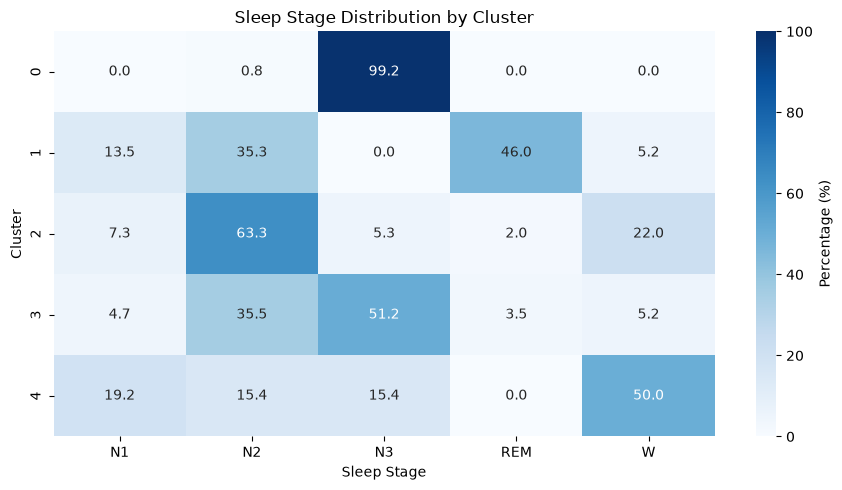

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(9, 5))

sns.heatmap(
    cluster_stage_ratio,
    annot=True,
    fmt=".1f",
    cmap="Blues",
    vmin=0,
    vmax=100,
    cbar_kws={"label": "Percentage (%)"}
)

plt.title("Sleep Stage Distribution by Cluster")
plt.xlabel("Sleep Stage")
plt.ylabel("Cluster")

plt.tight_layout()
plt.show()

In [19]:
from sklearn.metrics import (
    silhouette_score,
    adjusted_rand_score
)

# シルエットスコア
silhouette = silhouette_score(
    X_scaled,
    cluster_labels
)

# 実際の睡眠段階との一致度
ari = adjusted_rand_score(
    result_df["stage"],
    cluster_labels
)

print(f"シルエットスコア: {silhouette:.3f}")
print(f"ARI: {ari:.3f}")

シルエットスコア: 0.333
ARI: 0.254


,n_clusters,silhouette_score
0,2,0.394631
1,3,0.412118
2,4,0.323993
3,5,0.332651
4,6,0.332450
5,7,0.342167
6,8,0.339665


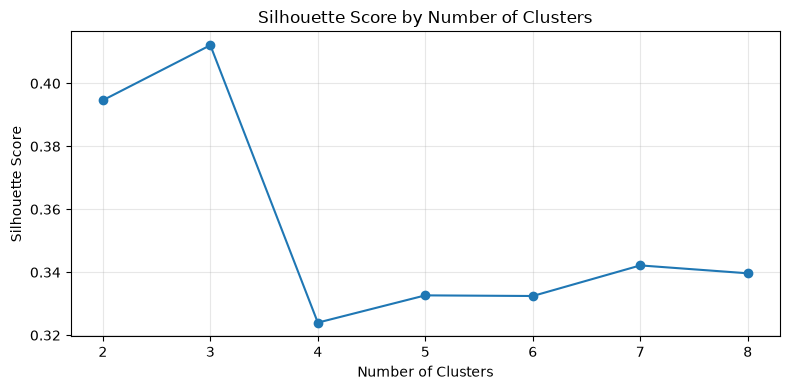

In [20]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import pandas as pd
import matplotlib.pyplot as plt

# クラスタ数を変えて評価
results = []

for k in range(2, 9):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_scaled)

    score = silhouette_score(X_scaled, labels)

    results.append({
        "n_clusters": k,
        "silhouette_score": score
    })

# 結果を表にする
evaluation_df = pd.DataFrame(results)

display(evaluation_df)

# グラフで比較
plt.figure(figsize=(8, 4))

plt.plot(
    evaluation_df["n_clusters"],
    evaluation_df["silhouette_score"],
    marker="o"
)

plt.title("Silhouette Score by Number of Clusters")
plt.xlabel("Number of Clusters")
plt.ylabel("Silhouette Score")
plt.xticks(range(2, 9))
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [21]:
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score
import pandas as pd

# クラスタ数3で再学習
kmeans_3 = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

cluster_labels_3 = kmeans_3.fit_predict(X_scaled)

# 結果をDataFrameにまとめる
result_3_df = features_df.copy()

result_3_df["cluster"] = cluster_labels_3
result_3_df["stage"] = epoch_df["stage_5"].values

# クラスタごとの睡眠段階の分布
cluster_stage_3 = pd.crosstab(
    result_3_df["cluster"],
    result_3_df["stage"]
)

print("クラスタごとの睡眠段階の分布：")
display(cluster_stage_3)

# クラスタ内の割合
cluster_stage_3_ratio = pd.crosstab(
    result_3_df["cluster"],
    result_3_df["stage"],
    normalize="index"
) * 100

print("\nクラスタ内の睡眠段階の割合（%）：")
display(cluster_stage_3_ratio.round(1))

# 睡眠段階との一致度
ari_3 = adjusted_rand_score(
    result_3_df["stage"],
    cluster_labels_3
)

print(f"\n3クラスタのARI：{ari_3:.3f}")

クラスタごとの睡眠段階の分布：


stage,N1,N2,N3,REM,W
cluster,,,,,
0,5,5,5,0,15
1,53,206,27,122,45
2,0,39,188,3,8



クラスタ内の睡眠段階の割合（%）：


stage,N1,N2,N3,REM,W
cluster,,,,,
0,16.7,16.7,16.7,0.0,50.0
1,11.7,45.5,6.0,26.9,9.9
2,0.0,16.4,79.0,1.3,3.4



3クラスタのARI：0.244


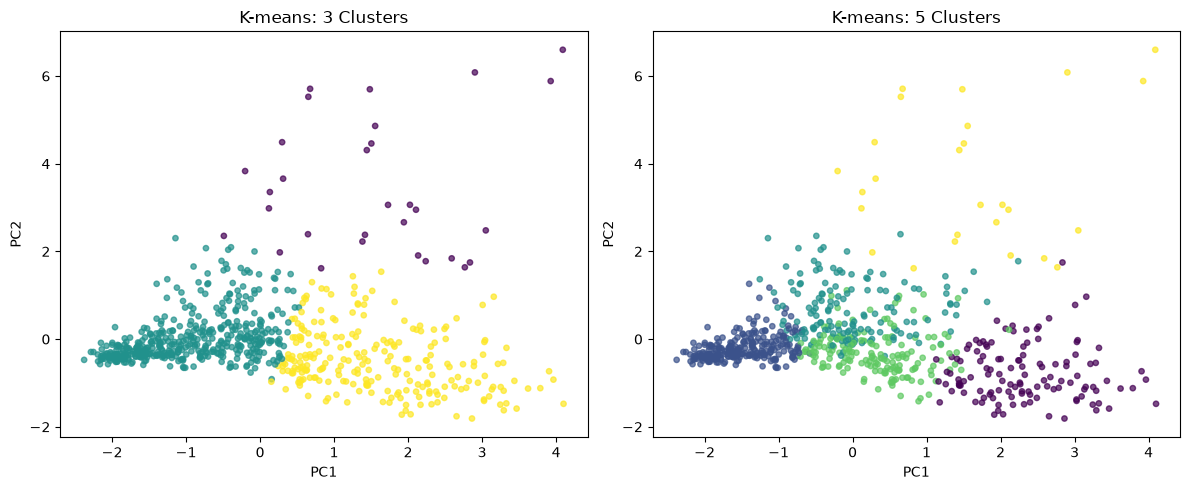

各主成分の寄与率：
[0.52852529 0.25771736]
2次元で説明できる分散の割合： 78.62 %


In [22]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

# 標準化済みの特徴量を2次元に圧縮
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

# 2つのグラフを並べて表示
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# 3クラスタ
axes[0].scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=cluster_labels_3,
    cmap="viridis",
    s=15,
    alpha=0.7
)
axes[0].set_title("K-means: 3 Clusters")
axes[0].set_xlabel("PC1")
axes[0].set_ylabel("PC2")

# 5クラスタ
axes[1].scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=cluster_labels,
    cmap="viridis",
    s=15,
    alpha=0.7
)
axes[1].set_title("K-means: 5 Clusters")
axes[1].set_xlabel("PC1")
axes[1].set_ylabel("PC2")

plt.tight_layout()
plt.show()

# PCAで保持できた情報の割合
print("各主成分の寄与率：")
print(pca.explained_variance_ratio_)

print(
    "2次元で説明できる分散の割合：",
    round(pca.explained_variance_ratio_.sum() * 100, 2),
    "%"
)

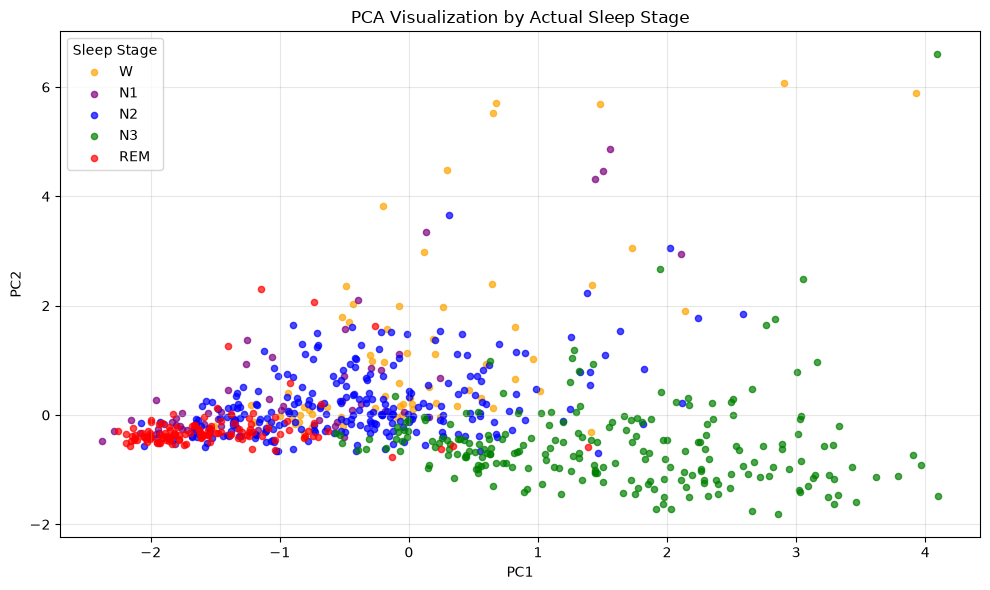

In [23]:
import matplotlib.pyplot as plt

# 睡眠段階の一覧
stages = ["W", "N1", "N2", "N3", "REM"]

# 睡眠段階ごとに色を設定
colors = {
    "W": "orange",
    "N1": "purple",
    "N2": "blue",
    "N3": "green",
    "REM": "red"
}

plt.figure(figsize=(10, 6))

# 睡眠段階ごとに散布図を作成
for stage in stages:

    mask = epoch_df["stage_5"] == stage

    plt.scatter(
        X_pca[mask, 0],
        X_pca[mask, 1],
        label=stage,
        color=colors[stage],
        s=20,
        alpha=0.7
    )

plt.title("PCA Visualization by Actual Sleep Stage")
plt.xlabel("PC1")
plt.ylabel("PC2")

plt.legend(title="Sleep Stage")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

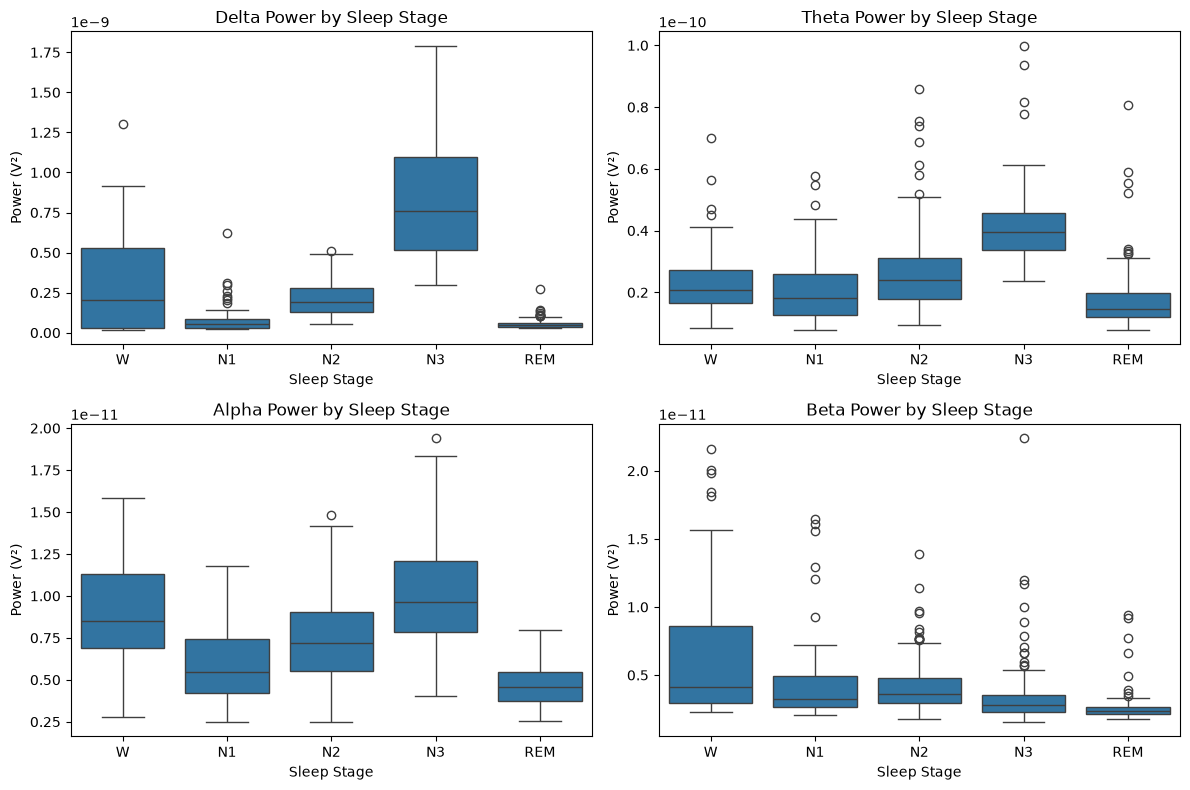

In [24]:
import matplotlib.pyplot as plt
import seaborn as sns

# 比較する周波数特徴量
features = ["delta", "theta", "alpha", "beta"]

# 睡眠段階の表示順
stage_order = ["W", "N1", "N2", "N3", "REM"]

# グラフを作成
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, feature in zip(axes.flat, features):

    sns.boxplot(
        data=result_df,
        x="stage",
        y=feature,
        order=stage_order,
        ax=ax
    )

    ax.set_title(f"{feature.capitalize()} Power by Sleep Stage")
    ax.set_xlabel("Sleep Stage")
    ax.set_ylabel("Power (V²)")

plt.tight_layout()
plt.show()

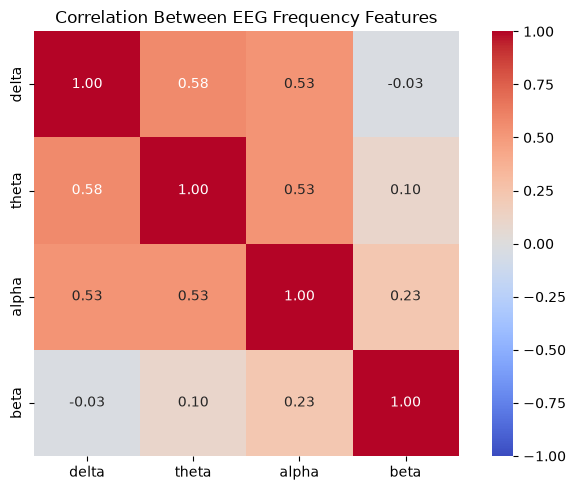

In [25]:
import matplotlib.pyplot as plt
import seaborn as sns

# 分析する4種類の特徴量
feature_columns = ["delta", "theta", "alpha", "beta"]

# 相関係数を計算
correlation = features_df[feature_columns].corr()

# ヒートマップを作成
plt.figure(figsize=(7, 5))

sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    square=True
)

plt.title("Correlation Between EEG Frequency Features")
plt.tight_layout()
plt.show()

In [26]:
import numpy as np
import pandas as pd

# 使用する周波数特徴量
feature_columns = ["delta", "theta", "alpha", "beta"]

# 絶対パワーを取得
absolute_power = features_df[feature_columns].copy()

# 各エポックの4周波数帯の合計
total_power = absolute_power.sum(axis=1)

# 相対パワーに変換
relative_power_df = absolute_power.div(
    total_power.replace(0, np.nan),
    axis=0
)

# 計算結果の確認
print("相対パワーのデータ形状:", relative_power_df.shape)

print("\n最初の5件:")
display(relative_power_df.head())

print("\n欠損値の数:")
print(relative_power_df.isna().sum())

print("\n各エポックの相対パワー合計:")
print(relative_power_df.sum(axis=1).head())

相対パワーのデータ形状: (721, 4)

最初の5件:


,delta,theta,alpha,beta
0,0.550453,0.277225,0.125416,0.046906
1,0.591739,0.303730,0.054197,0.050334
2,0.706459,0.222323,0.040499,0.030719
3,0.790701,0.175452,0.018826,0.015021
4,0.836314,0.134410,0.016436,0.012839



欠損値の数:
delta    0
theta    0
alpha    0
beta     0
dtype: int64

各エポックの相対パワー合計:
0    1.0
1    1.0
2    1.0
3    1.0
4    1.0
dtype: float64


In [27]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import adjusted_rand_score, silhouette_score
import pandas as pd

# 相対パワーを標準化
scaler_relative = StandardScaler()
X_relative = scaler_relative.fit_transform(relative_power_df)

# 結果を保存するリスト
comparison_results = []

# 3クラスタと5クラスタで比較
for n_clusters in [3, 5]:

    kmeans_relative = KMeans(
        n_clusters=n_clusters,
        random_state=42,
        n_init=10
    )

    # クラスタリング
    labels_relative = kmeans_relative.fit_predict(X_relative)

    # シルエットスコア
    silhouette = silhouette_score(
        X_relative,
        labels_relative
    )

    # 実際の睡眠段階との一致度
    ari = adjusted_rand_score(
        epoch_df["stage_5"],
        labels_relative
    )

    comparison_results.append({
        "n_clusters": n_clusters,
        "silhouette_score": silhouette,
        "ARI": ari
    })

# 結果を表にする
comparison_df = pd.DataFrame(comparison_results)

display(comparison_df.round(3))

,n_clusters,silhouette_score,ARI
0,3,0.535,0.273
1,5,0.466,0.443


In [28]:
# 相対パワーによる5クラスタの結果を取得
kmeans_relative_5 = KMeans(
    n_clusters=5,
    random_state=42,
    n_init=10
)

labels_relative_5 = kmeans_relative_5.fit_predict(X_relative)

# 結果をDataFrameにまとめる
relative_result_df = relative_power_df.copy()

relative_result_df["cluster"] = labels_relative_5
relative_result_df["stage"] = epoch_df["stage_5"].to_numpy()

# クラスタごとの睡眠段階の件数
cluster_stage_counts = pd.crosstab(
    relative_result_df["cluster"],
    relative_result_df["stage"]
)

# クラスタ内の割合（%）
cluster_stage_ratio = pd.crosstab(
    relative_result_df["cluster"],
    relative_result_df["stage"],
    normalize="index"
) * 100

print("クラスタごとの睡眠段階の件数:")
display(cluster_stage_counts)

print("\nクラスタ内の睡眠段階の割合（%）:")
display(cluster_stage_ratio.round(1))

クラスタごとの睡眠段階の件数:


stage,N1,N2,N3,REM,W
cluster,,,,,
0,1,75,216,1,27
1,21,12,0,100,5
2,15,162,4,18,12
3,11,0,0,2,21
4,10,1,0,4,3



クラスタ内の睡眠段階の割合（%）:


stage,N1,N2,N3,REM,W
cluster,,,,,
0,0.3,23.4,67.5,0.3,8.4
1,15.2,8.7,0.0,72.5,3.6
2,7.1,76.8,1.9,8.5,5.7
3,32.4,0.0,0.0,5.9,61.8
4,55.6,5.6,0.0,22.2,16.7


In [29]:
# 睡眠段階ごとに、各クラスタへ分かれた割合を確認
stage_cluster_ratio = pd.crosstab(
    relative_result_df["stage"],
    relative_result_df["cluster"],
    normalize="index"
) * 100

print("睡眠段階ごとのクラスタ分布（%）:")
display(stage_cluster_ratio.round(1))

睡眠段階ごとのクラスタ分布（%）:


cluster,0,1,2,3,4
stage,,,,,
N1,1.7,36.2,25.9,19.0,17.2
N2,30.0,4.8,64.8,0.0,0.4
N3,98.2,0.0,1.8,0.0,0.0
REM,0.8,80.0,14.4,1.6,3.2
W,39.7,7.4,17.6,30.9,4.4


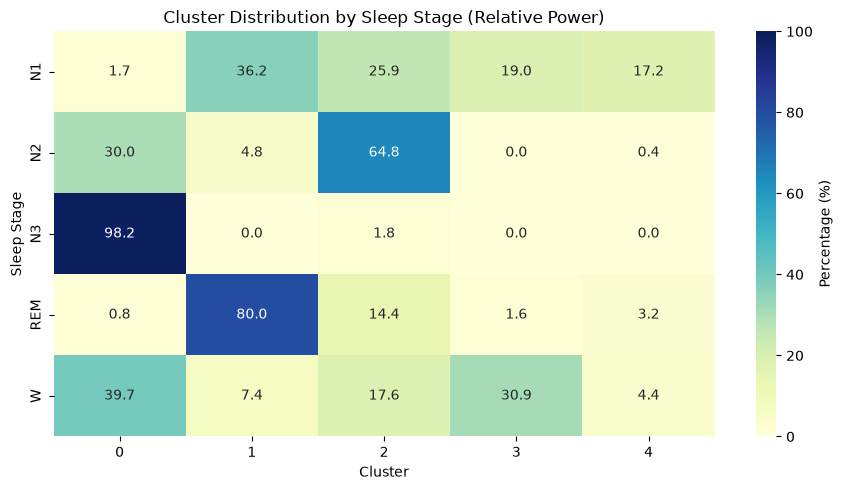

In [30]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(9, 5))

sns.heatmap(
    stage_cluster_ratio,
    annot=True,
    fmt=".1f",
    cmap="YlGnBu",
    vmin=0,
    vmax=100,
    cbar_kws={"label": "Percentage (%)"}
)

plt.title("Cluster Distribution by Sleep Stage (Relative Power)")
plt.xlabel("Cluster")
plt.ylabel("Sleep Stage")

plt.tight_layout()
plt.show()

In [31]:
import numpy as np

# 既存の相対パワー特徴量をコピー
extended_features_df = relative_power_df.copy()

# ゼロ除算を防ぐための微小値
eps = 1e-10

# 新しい特徴量を追加
extended_features_df["delta_theta_ratio"] = (
    extended_features_df["delta"] /
    (extended_features_df["theta"] + eps)
)

extended_features_df["alpha_theta_ratio"] = (
    extended_features_df["alpha"] /
    (extended_features_df["theta"] + eps)
)

# 結果を確認
print("特徴量データの形状:", extended_features_df.shape)

display(extended_features_df.head())

print("\n欠損値の数:")
print(extended_features_df.isna().sum())

特徴量データの形状: (721, 6)


,delta,theta,alpha,beta,delta_theta_ratio,alpha_theta_ratio
0,0.550453,0.277225,0.125416,0.046906,1.985582,0.452397
1,0.591739,0.303730,0.054197,0.050334,1.948237,0.178437
2,0.706459,0.222323,0.040499,0.030719,3.177626,0.182162
3,0.790701,0.175452,0.018826,0.015021,4.506651,0.107298
4,0.836314,0.134410,0.016436,0.012839,6.222121,0.122286



欠損値の数:
delta                0
theta                0
alpha                0
beta                 0
delta_theta_ratio    0
alpha_theta_ratio    0
dtype: int64


In [32]:
from sklearn.preprocessing import StandardScaler

# 6種類の特徴量を標準化
scaler_extended = StandardScaler()

X_extended = scaler_extended.fit_transform(
    extended_features_df
)

# 結果を確認
print("標準化後のデータ形状:", X_extended.shape)

print("\n平均:")
print(X_extended.mean(axis=0).round(3))

print("\n標準偏差:")
print(X_extended.std(axis=0).round(3))

標準化後のデータ形状: (721, 6)

平均:
[-0.  0.  0.  0. -0. -0.]

標準偏差:
[1. 1. 1. 1. 1. 1.]


In [33]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score
import pandas as pd

# 比較結果を保存するリスト
extended_results = []

# クラスタ数3と5で比較
for n_clusters in [3, 5]:

    kmeans_extended = KMeans(
        n_clusters=n_clusters,
        random_state=42,
        n_init=10
    )

    # 6特徴量でクラスタリング
    labels_extended = kmeans_extended.fit_predict(X_extended)

    # シルエットスコア
    silhouette = silhouette_score(
        X_extended,
        labels_extended
    )

    # 実際の睡眠段階との一致度
    ari = adjusted_rand_score(
        epoch_df["stage_5"],
        labels_extended
    )

    extended_results.append({
        "n_clusters": n_clusters,
        "silhouette_score": silhouette,
        "ARI": ari
    })

# 結果を表示
extended_comparison_df = pd.DataFrame(extended_results)

display(extended_comparison_df.round(3))

,n_clusters,silhouette_score,ARI
0,3,0.397,0.289
1,5,0.370,0.339


In [34]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score
import pandas as pd

# 元の4特徴量＋delta_theta_ratio
features_5_df = extended_features_df[
    ["delta", "theta", "alpha", "beta", "delta_theta_ratio"]
].copy()

# 標準化
scaler_5 = StandardScaler()
X_5 = scaler_5.fit_transform(features_5_df)

# クラスタ数3・5で比較
results_5 = []

for n_clusters in [3, 5]:

    kmeans_5 = KMeans(
        n_clusters=n_clusters,
        random_state=42,
        n_init=10
    )

    labels_5 = kmeans_5.fit_predict(X_5)

    silhouette = silhouette_score(X_5, labels_5)

    ari = adjusted_rand_score(
        epoch_df["stage_5"],
        labels_5
    )

    results_5.append({
        "n_clusters": n_clusters,
        "silhouette_score": silhouette,
        "ARI": ari
    })

# 結果を表示
comparison_5_df = pd.DataFrame(results_5)

display(comparison_5_df.round(3))

,n_clusters,silhouette_score,ARI
0,3,0.418,0.436
1,5,0.399,0.351


In [35]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score
import pandas as pd

# 元の4特徴量＋alpha_theta_ratio
features_alpha_df = extended_features_df[
    ["delta", "theta", "alpha", "beta", "alpha_theta_ratio"]
].copy()

# 標準化
scaler_alpha = StandardScaler()
X_alpha = scaler_alpha.fit_transform(features_alpha_df)

# 3クラスタ・5クラスタで比較
results_alpha = []

for n_clusters in [3, 5]:

    kmeans_alpha = KMeans(
        n_clusters=n_clusters,
        random_state=42,
        n_init=10
    )

    labels_alpha = kmeans_alpha.fit_predict(X_alpha)

    silhouette = silhouette_score(X_alpha, labels_alpha)

    ari = adjusted_rand_score(
        epoch_df["stage_5"],
        labels_alpha
    )

    results_alpha.append({
        "n_clusters": n_clusters,
        "silhouette_score": silhouette,
        "ARI": ari
    })

# 結果を表示
comparison_alpha_df = pd.DataFrame(results_alpha)

display(comparison_alpha_df.round(3))

,n_clusters,silhouette_score,ARI
0,3,0.462,0.278
1,5,0.363,0.488


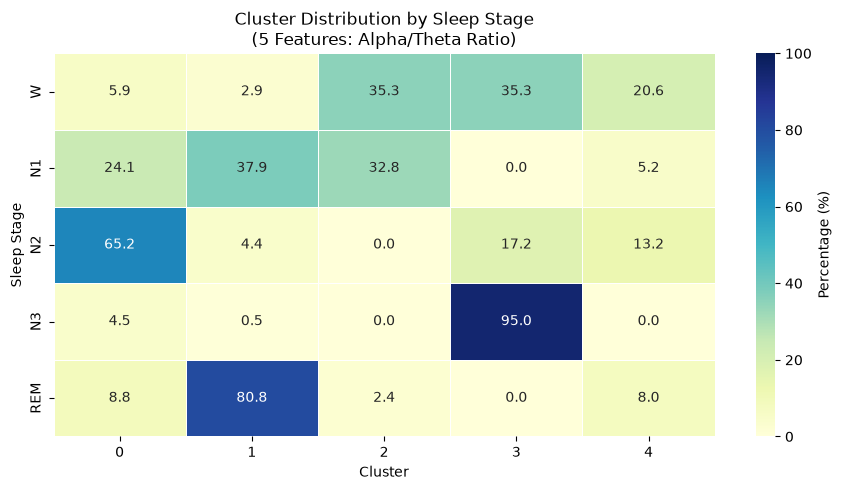

In [36]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 5特徴量（alpha/theta比を追加）の5クラスタ結果を取得
# ※前のセルで作成した labels_alpha を使用
alpha_result_df = pd.DataFrame({
    "stage": epoch_df["stage_5"].to_numpy(),
    "cluster": labels_alpha
})

# 睡眠段階ごとのクラスタ分布（割合）
alpha_stage_cluster_ratio = pd.crosstab(
    alpha_result_df["stage"],
    alpha_result_df["cluster"],
    normalize="index"
) * 100

# 睡眠段階の表示順を指定
stage_order = ["W", "N1", "N2", "N3", "REM"]

alpha_stage_cluster_ratio = alpha_stage_cluster_ratio.reindex(
    stage_order
)

# ヒートマップを作成
plt.figure(figsize=(9, 5))

sns.heatmap(
    alpha_stage_cluster_ratio,
    annot=True,
    fmt=".1f",
    cmap="YlGnBu",
    vmin=0,
    vmax=100,
    linewidths=0.5,
    cbar_kws={"label": "Percentage (%)"}
)

plt.title(
    "Cluster Distribution by Sleep Stage\n"
    "(5 Features: Alpha/Theta Ratio)"
)

plt.xlabel("Cluster")
plt.ylabel("Sleep Stage")

plt.tight_layout()
plt.show()

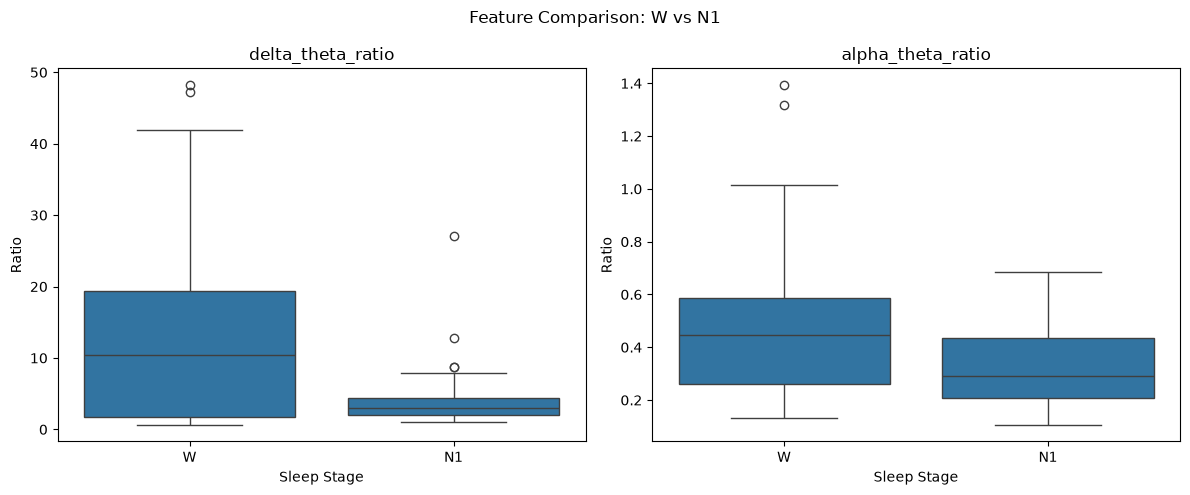

In [37]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 既存の6特徴量データに睡眠段階を追加
comparison_df = extended_features_df.copy()

comparison_df["stage"] = epoch_df["stage_5"].to_numpy()

# WとN1のみ抽出
wn1_df = comparison_df[
    comparison_df["stage"].isin(["W", "N1"])
].copy()

# 比較する特徴量
features = [
    "delta_theta_ratio",
    "alpha_theta_ratio"
]

# 箱ひげ図
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, feature in zip(axes, features):
    sns.boxplot(
        data=wn1_df,
        x="stage",
        y=feature,
        order=["W", "N1"],
        ax=ax
    )

    ax.set_title(feature)
    ax.set_xlabel("Sleep Stage")
    ax.set_ylabel("Ratio")

plt.suptitle("Feature Comparison: W vs N1")

plt.tight_layout()
plt.show()

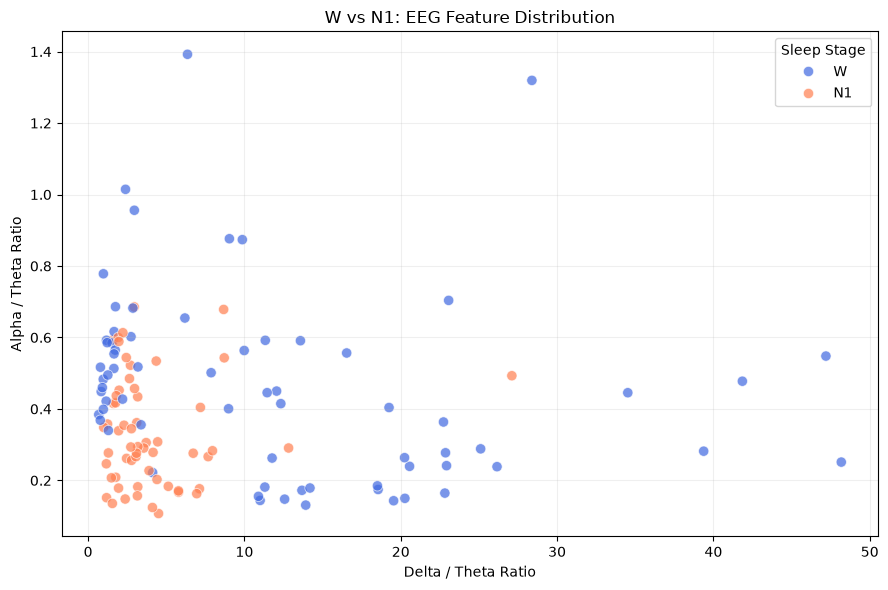

In [38]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=wn1_df,
    x="delta_theta_ratio",
    y="alpha_theta_ratio",
    hue="stage",
    hue_order=["W", "N1"],
    palette={"W": "royalblue", "N1": "coral"},
    alpha=0.7,
    s=55
)

plt.title("W vs N1: EEG Feature Distribution")
plt.xlabel("Delta / Theta Ratio")
plt.ylabel("Alpha / Theta Ratio")
plt.legend(title="Sleep Stage")
plt.grid(alpha=0.2)

plt.tight_layout()
plt.show()

In [39]:
# 比較する特徴量
features = [
    "delta_theta_ratio",
    "alpha_theta_ratio"
]

# 睡眠段階ごとの統計量
summary_df = (
    wn1_df.groupby("stage")[features]
    .agg(["count", "median", "mean", "std",
          lambda x: x.quantile(0.25),
          lambda x: x.quantile(0.75)])
)

# 列名を整理
summary_df.columns = [
    f"{feature}_{stat}"
    for feature, stat in summary_df.columns
]

summary_df = summary_df.rename(
    columns=lambda x: x.replace("<lambda_0>", "Q1")
                       .replace("<lambda_1>", "Q3")
)

# 四分位範囲（IQR）を追加
for feature in features:
    summary_df[f"{feature}_IQR"] = (
        summary_df[f"{feature}_Q3"]
        - summary_df[f"{feature}_Q1"]
    )

# 表示
display(summary_df.round(3))

,delta_theta_ratio_count,delta_theta_ratio_median,delta_theta_ratio_mean,delta_theta_ratio_std,delta_theta_ratio_Q1,delta_theta_ratio_Q3,alpha_theta_ratio_count,alpha_theta_ratio_median,alpha_theta_ratio_mean,alpha_theta_ratio_std,alpha_theta_ratio_Q1,alpha_theta_ratio_Q3,delta_theta_ratio_IQR,alpha_theta_ratio_IQR
stage,,,,,,,,,,,,,,
N1,58,3.016,4.059,3.879,1.957,4.440,58,0.292,0.334,0.153,0.208,0.436,2.483,0.229
W,68,10.441,12.117,11.811,1.716,19.324,68,0.445,0.462,0.261,0.260,0.585,17.608,0.325


In [40]:
# WとN1の比較に必要な指標を抽出
comparison_table = summary_df[
    [
        "delta_theta_ratio_count",
        "delta_theta_ratio_median",
        "delta_theta_ratio_IQR",
        "alpha_theta_ratio_median",
        "alpha_theta_ratio_IQR"
    ]
].copy()

# 列名をわかりやすく変更
comparison_table.columns = [
    "データ数",
    "Delta/Theta 中央値",
    "Delta/Theta IQR",
    "Alpha/Theta 中央値",
    "Alpha/Theta IQR"
]

# W → N1の順番に並べる
comparison_table = comparison_table.reindex(["W", "N1"])

# 表示
display(comparison_table.round(3))

,データ数,Delta/Theta 中央値,Delta/Theta IQR,Alpha/Theta 中央値,Alpha/Theta IQR
stage,,,,,
W,68,10.441,17.608,0.445,0.325
N1,58,3.016,2.483,0.292,0.229


In [41]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, adjusted_rand_score
import pandas as pd

# 比較する特徴量の組み合わせ
feature_sets = {
    "A：Delta/Theta": [
        "delta_theta_ratio"
    ],
    "B：2つの比率": [
        "delta_theta_ratio",
        "alpha_theta_ratio"
    ],
    "C：2つの比率＋Beta": [
        "delta_theta_ratio",
        "alpha_theta_ratio",
        "beta"
    ]
}

results = []

# 特徴量の組み合わせごとに検証
for feature_name, columns in feature_sets.items():

    # 特徴量を抽出して標準化
    X = extended_features_df[columns].copy()
    X_scaled = StandardScaler().fit_transform(X)

    for n_clusters in [3, 5]:

        # KMeansによるクラスタリング
        model = KMeans(
            n_clusters=n_clusters,
            random_state=42,
            n_init=10
        )

        labels = model.fit_predict(X_scaled)

        # 評価指標
        silhouette = silhouette_score(X_scaled, labels)

        ari = adjusted_rand_score(
            epoch_df["stage_5"],
            labels
        )

        results.append({
            "特徴量": feature_name,
            "クラスタ数": n_clusters,
            "シルエットスコア": silhouette,
            "ARI": ari
        })

# 結果を表にまとめる
feature_comparison_df = pd.DataFrame(results)

display(
    feature_comparison_df.round(3)
)

,特徴量,クラスタ数,シルエットスコア,ARI
0,A：Delta/Theta,3,0.594,0.179
1,A：Delta/Theta,5,0.588,0.259
2,B：2つの比率,3,0.452,0.143
3,B：2つの比率,5,0.391,0.190
4,C：2つの比率＋Beta,3,0.360,0.208
5,C：2つの比率＋Beta,5,0.367,0.253


In [42]:
import pandas as pd
from pathlib import Path

# 相対パワーと睡眠段階を結合
physiology_df = relative_power_df.copy()

physiology_df["stage"] = epoch_df["stage_5"].to_numpy()

# 保存先のフォルダを作成
output_dir = Path("../data/processed")
output_dir.mkdir(parents=True, exist_ok=True)

# CSVに保存
output_path = output_dir / "sleep_physiology_features.csv"
physiology_df.to_csv(output_path, index=False)

print("保存先:", output_path)
print("データサイズ:", physiology_df.shape)

display(physiology_df.head())

保存先: ..\data\processed\sleep_physiology_features.csv
データサイズ: (721, 5)


,delta,theta,alpha,beta,stage
0,0.550453,0.277225,0.125416,0.046906,N1
1,0.591739,0.303730,0.054197,0.050334,N1
2,0.706459,0.222323,0.040499,0.030719,N1
3,0.790701,0.175452,0.018826,0.015021,N1
4,0.836314,0.134410,0.016436,0.012839,N2


In [43]:
# エポックと時間情報の確認
print("エポック数:", len(epoch_df))
print("相対パワーのデータ数:", len(relative_power_df))

print("\n開始時刻の先頭10件:")
display(epoch_df[["epoch", "start_sec", "stage_5"]].head(10))

print("\n開始時刻の最後10件:")
display(epoch_df[["epoch", "start_sec", "stage_5"]].tail(10))

# 時間が単調増加しているか確認
print(
    "\n時間順に並んでいるか:",
    epoch_df["start_sec"].is_monotonic_increasing
)

# エポック番号が0から連続しているか確認
print(
    "エポック番号が連続しているか:",
    (epoch_df["epoch"].to_numpy() == np.arange(len(epoch_df))).all()
)

エポック数: 721
相対パワーのデータ数: 721

開始時刻の先頭10件:


,epoch,start_sec,stage_5
0,0,30630.0,N1
1,1,30660.0,N1
2,2,30690.0,N1
3,3,30720.0,N1
4,4,30750.0,N2
5,5,30780.0,N2
6,6,30810.0,N2
7,7,30840.0,N2
8,8,30870.0,N2
9,9,30900.0,N2



開始時刻の最後10件:


,epoch,start_sec,stage_5
711,711,51960.0,W
712,712,51990.0,W
713,713,52020.0,W
714,714,52050.0,W
715,715,52080.0,W
716,716,52110.0,N1
717,717,52140.0,N1
718,718,52170.0,N1
719,719,52200.0,N1
720,720,52230.0,N1



時間順に並んでいるか: True
エポック番号が連続しているか: True


In [44]:
# 相対パワーと時間情報の行数を確認
assert len(relative_power_df) == len(epoch_df), "行数が一致しません"

# エポック番号と時間が順番どおりか確認
assert (
    epoch_df["epoch"].to_numpy() == np.arange(len(epoch_df))
).all(), "エポック番号が連続していません"

assert epoch_df["start_sec"].is_monotonic_increasing, "時間順ではありません"

# 相対パワーと睡眠段階・時間情報を結合
physiology_df = relative_power_df.reset_index(drop=True).copy()

physiology_df["stage"] = epoch_df["stage_5"].to_numpy()
physiology_df["epoch"] = epoch_df["epoch"].to_numpy()
physiology_df["start_sec"] = epoch_df["start_sec"].to_numpy()

# CSVを更新
output_path = output_dir / "sleep_physiology_features.csv"
physiology_df.to_csv(output_path, index=False)

print("保存先:", output_path)
print("データサイズ:", physiology_df.shape)

display(physiology_df.head())

保存先: ..\data\processed\sleep_physiology_features.csv
データサイズ: (721, 7)


,delta,theta,alpha,beta,stage,epoch,start_sec
0,0.550453,0.277225,0.125416,0.046906,N1,0,30630.0
1,0.591739,0.303730,0.054197,0.050334,N1,1,30660.0
2,0.706459,0.222323,0.040499,0.030719,N1,2,30690.0
3,0.790701,0.175452,0.018826,0.015021,N1,3,30720.0
4,0.836314,0.134410,0.016436,0.012839,N2,4,30750.0


## 結果と考察

### 1. クラスタリング結果

KMeansを用いて睡眠段階のクラスタリングを行い、特徴量の違いによる分類結果を比較した。

5クラスタで比較した結果、絶対パワー4種類を使用した場合のARIは0.254、相対パワー4種類では0.443、相対パワー4種類にAlpha/Theta比を追加した場合は0.488となった。

今回比較した条件では、相対パワーとAlpha/Theta比を組み合わせた場合に、最も高いARIが得られた。

### 2. 考察

絶対パワーよりも相対パワーを使用した場合にARIが高くなったことから、今回のデータでは、各周波数帯域のパワーの大きさだけでなく、帯域間の割合が睡眠段階の違いを捉えるうえで有効だった可能性がある。

また、Alpha/Theta比の追加によってARIがさらに向上したことから、周波数帯域間の関係を特徴量として取り入れることにも一定の効果があったと考えられる。

一方、最も高いARIは0.488にとどまり、実際の睡眠段階との一致には限界があった。睡眠段階によって脳波の特徴が重なることや、今回使用した特徴量だけでは十分に区別できないことが影響した可能性がある。

### 3. 今後の課題

今回の分析では、EEGの周波数特徴量を中心にクラスタリングを行った。

今後は、EOGやEMGなどの生体信号を組み合わせることや、時間的な変化を考慮した分析によって、睡眠段階の特徴をより詳しく捉えられる可能性がある。

ただし、これらは今後の検討課題であり、今回の分析では実施していない。